## 1. Chargement des données

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 20)

In [27]:
chemin = "FC26_20250921.csv"
df = pd.read_csv(chemin, low_memory=False)

print("Nombre de lignes (joueurs) :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
df[["short_name", "age", "player_positions", "overall", "potential", "value_eur"]].head()

Nombre de lignes (joueurs) : 18405
Nombre de colonnes : 110


,short_name,age,player_positions,overall,potential,value_eur
0,J. Bellingham,22,"CAM, CM",90,94,174500000
1,F. Valverde,26,"CM, CDM, RB",89,90,120500000
2,J. Kimmich,30,"CDM, RB, CM",89,89,86000000
3,A. Hakimi,26,"RB, RM",89,90,111000000
4,N. Barella,28,CM,87,87,79500000


## 2. Exploration et nettoyage

### 2.1 Types des colonnes

In [28]:
print(df.dtypes.value_counts())
print()
colonnes_cles = ["short_name", "age", "player_positions", "overall", "potential", "value_eur", "movement_reactions", "pace"]
print(df[colonnes_cles].dtypes)

int64      48
str        46
float64    16
Name: count, dtype: int64

short_name                str
age                     int64
player_positions          str
overall                 int64
potential               int64
value_eur               int64
movement_reactions      int64
pace                  float64
dtype: object


Les colonnes numériques (âge, note, valeur, statistiques) ont bien un type numérique. La colonne `player_positions` est du texte (par exemple `"CAM, CM"`), on en extraira le poste plus loin.

### 2.2 Valeurs manquantes

In [29]:
pourcentage_manquant = (df.isna().mean() * 100).round(1)
pourcentage_manquant = pourcentage_manquant[pourcentage_manquant > 0].sort_values(ascending=False)
print("Colonnes avec des valeurs manquantes (en %) :")
print(pourcentage_manquant.head(12))

print()
print("Valeurs manquantes sur les colonnes importantes :")
print(df[["age", "overall", "potential", "value_eur", "player_positions"]].isna().sum())

Colonnes avec des valeurs manquantes (en %) :
work_rate               100.0
nation_team_id           96.0
nation_position          96.0
nation_jersey_number     96.0
player_tags              94.8
club_loaned_from         92.8
goalkeeping_speed        88.8
player_traits            58.6
passing                  11.2
dribbling                11.2
defending                11.2
pace                     11.2
dtype: float64

Valeurs manquantes sur les colonnes importantes :
age                 0
overall             0
potential           0
value_eur           0
player_positions    0
dtype: int64


Les colonnes importantes pour l'analyse (âge, note, potentiel, valeur, poste) n'ont **aucune valeur manquante**. Les colonnes comme `pace`, `shooting` ou `dribbling` manquent pour environ 11 % des joueurs : ce sont les **gardiens**, qui n'ont pas ces notes. Ce n'est pas une erreur, donc on ne les supprime pas.

### 2.3 Doublons

In [30]:
print("Lignes entièrement dupliquées :", df.duplicated().sum())
print("Identifiants de joueurs dupliqués :", df["player_id"].duplicated().sum())

Lignes entièrement dupliquées : 0
Identifiants de joueurs dupliqués : 0


Il n'y a **aucun doublon** : chaque ligne correspond à un joueur unique.

### 2.4 Valeurs suspectes

In [31]:
print("Âge       : min =", df["age"].min(), "| max =", df["age"].max())
print("Note      : min =", df["overall"].min(), "| max =", df["overall"].max())
print("Potentiel inférieur à la note :", (df["potential"] < df["overall"]).sum(), "joueurs")
print("Valeur marchande = 0 :", (df["value_eur"] == 0).sum(), "joueurs")

# Les statistiques techniques doivent être entre 0 et 100
colonnes_stats = [c for c in df.columns if c.startswith(("attacking_", "skill_", "movement_", "power_", "mentality_", "defending_", "goalkeeping_"))]
hors_limites = ((df[colonnes_stats] < 0) | (df[colonnes_stats] > 100)).sum().sum()
print("Statistiques hors de l'intervalle 0-100 :", hors_limites)

Âge       : min = 16 | max = 44
Note      : min = 47 | max = 91
Potentiel inférieur à la note : 0 joueurs
Valeur marchande = 0 : 109 joueurs
Statistiques hors de l'intervalle 0-100 : 0


Les âges (16 à 44 ans) et les notes (47 à 91) sont cohérents, et aucune statistique n'est hors limites. Le seul point suspect est que **109 joueurs ont une valeur marchande de 0 €** (valeur non renseignée, par exemple joueurs sans contrat). Ils ne permettent pas de comparer les prix, donc on les retire.

### 2.5 Nettoyage et nouvelles colonnes

In [32]:
# On enlève les joueurs sans valeur marchande
df = df[df["value_eur"] > 0].copy()

# Valeur en millions d'euros (plus lisible)
df["valeur_M"] = df["value_eur"] / 1000000


# Poste : on regarde la première position du joueur
def trouver_poste(positions):
    premiere = positions.split(",")[0].strip()   # "CAM, CM" devient "CAM"
    if premiere == "GK":
        return "Gardien"
    elif premiere in ["CB", "LB", "RB", "LWB", "RWB"]:
        return "Défenseur"
    elif premiere in ["CDM", "CM", "CAM", "LM", "RM"]:
        return "Milieu"
    else:
        return "Attaquant"


df["poste"] = df["player_positions"].apply(trouver_poste)

print("Joueurs conservés :", len(df))
df["poste"].value_counts()

Joueurs conservés : 18296


poste
Milieu       6827
Défenseur    6083
Attaquant    3336
Gardien      2050
Name: count, dtype: int64

## 3. Statistiques descriptives

In [33]:
df[["age", "overall", "potential", "valeur_M"]].describe().round(2)

,age,overall,potential,valeur_M
count,18296.00,18296.00,18296.00,18296.00
mean,25.19,65.74,71.16,2.95
std,4.75,6.98,6.41,7.97
min,16.00,47.00,49.00,0.01
25%,21.00,61.00,67.00,0.48
50%,25.00,66.00,71.00,1.00
75%,29.00,70.00,75.00,2.10
max,44.00,91.00,95.00,174.50


In [34]:
print("Valeur marchande (en millions d'euros)")
print("Moyenne  :", round(df["valeur_M"].mean(), 2))
print("Médiane  :", round(df["valeur_M"].median(), 2))
print("Écart-type :", round(df["valeur_M"].std(), 2))
print("Maximum  :", round(df["valeur_M"].max(), 1))
print("Asymétrie (skewness) :", round(df["valeur_M"].skew(), 1))

Valeur marchande (en millions d'euros)
Moyenne  : 2.95
Médiane  : 1.0
Écart-type : 7.97
Maximum  : 174.5
Asymétrie (skewness) : 8.6


**Lecture :** la valeur moyenne (environ 3 M€) est nettement supérieure à la médiane (environ 1 M€), et l'écart-type est très grand. Quelques stars valent plus de 100 M€ et tirent la moyenne vers le haut. Pour comparer des joueurs, on utilisera donc la **médiane**, plus fiable.

In [35]:
resume_poste = df.groupby("poste").agg(
    nb_joueurs=("overall", "count"),
    note_moyenne=("overall", "mean"),
    age_moyen=("age", "mean"),
    valeur_mediane_M=("valeur_M", "median"),
    valeur_moyenne_M=("valeur_M", "mean"),
).round(2)
resume_poste["part_%"] = (resume_poste["nb_joueurs"] / len(df) * 100).round(1)
resume_poste

,nb_joueurs,note_moyenne,age_moyen,valeur_mediane_M,valeur_moyenne_M,part_%
poste,,,,,,
Attaquant,3336,65.43,24.72,1.00,3.26,18.2
Défenseur,6083,65.96,25.52,1.00,2.62,33.2
Gardien,2050,64.20,26.26,0.52,1.83,11.2
Milieu,6827,66.17,24.80,1.20,3.43,37.3


Les notes moyennes sont proches d'un poste à l'autre (environ 64 à 66), mais les milieux et les attaquants ont une valeur moyenne plus élevée que les défenseurs et les gardiens.

## 4. Question 1 : quelles statistiques sont les plus liées à la note globale ?

On calcule la **corrélation** (entre -1 et 1) de chaque statistique avec la note `overall`. Plus elle est proche de 1, plus la statistique évolue avec la note. On exclut les gardiens, car leurs statistiques sont très différentes.

In [36]:
stats = ["attacking_finishing", "attacking_short_passing", "skill_dribbling",
         "skill_ball_control", "skill_long_passing", "movement_reactions",
         "movement_sprint_speed", "power_shot_power", "power_stamina",
         "power_strength", "mentality_vision", "mentality_composure",
         "mentality_interceptions", "defending_standing_tackle"]

joueurs_champ = df[df["poste"] != "Gardien"]

correlation = joueurs_champ[stats + ["overall"]].corr()["overall"].drop("overall")
correlation = correlation.sort_values(ascending=False)
print(correlation.round(2))

movement_reactions           0.89
mentality_composure          0.82
attacking_short_passing      0.81
skill_ball_control           0.79
skill_long_passing           0.66
skill_dribbling              0.60
mentality_vision             0.58
power_shot_power             0.56
power_stamina                0.55
attacking_finishing          0.40
power_strength               0.36
mentality_interceptions      0.34
defending_standing_tackle    0.32
movement_sprint_speed        0.23
Name: overall, dtype: float64


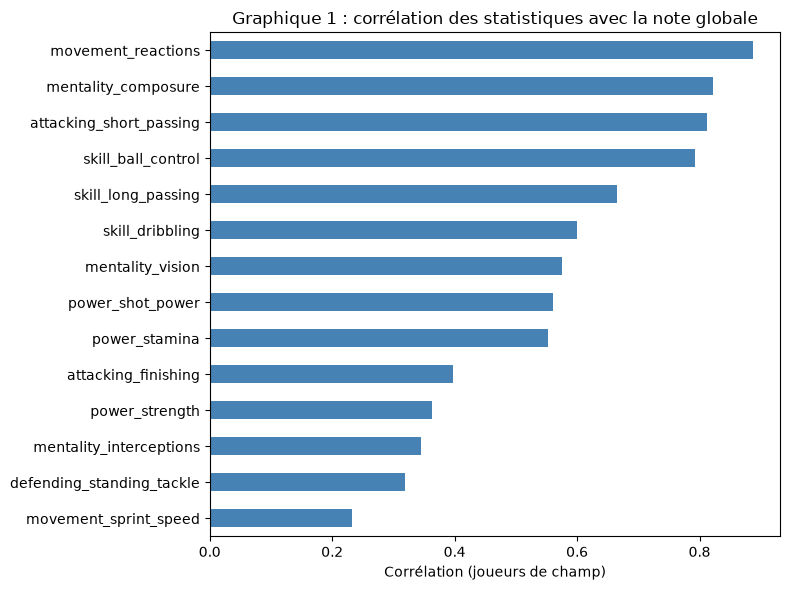

In [37]:
# Graphique 1 : corrélation avec la note globale
correlation.sort_values().plot(kind="barh", color="steelblue", figsize=(8, 6))
plt.title("Graphique 1 : corrélation des statistiques avec la note globale")
plt.xlabel("Corrélation (joueurs de champ)")
plt.tight_layout()
plt.show()

**Réponse :** les statistiques les plus liées à la note sont les **réactions** (`movement_reactions`, 0,89), le **sang-froid** (`mentality_composure`, 0,82), les **passes courtes** (0,81) et le **contrôle de balle** (0,79). Ce sont des qualités techniques et mentales. Les qualités physiques sont moins liées à la note : la vitesse de sprint n'a qu'une corrélation de 0,23.



## 5. Question 2 : comment la valeur marchande évolue-t-elle avec l'âge ?

In [38]:
valeur_par_age = df.groupby("age")["valeur_M"].median()
print(valeur_par_age.round(2))

age
16    0.39
17    0.40
18    0.48
19    0.55
20    0.70
21    1.00
22    1.30
23    1.40
24    1.40
25    1.40
26    1.40
27    1.30
28    1.20
29    1.20
30    1.10
31    0.88
32    0.90
33    0.68
34    0.45
35    0.35
36    0.25
37    0.25
38    0.28
39    0.24
40    0.09
41    0.08
42    0.10
43    0.08
44    0.18
Name: valeur_M, dtype: float64


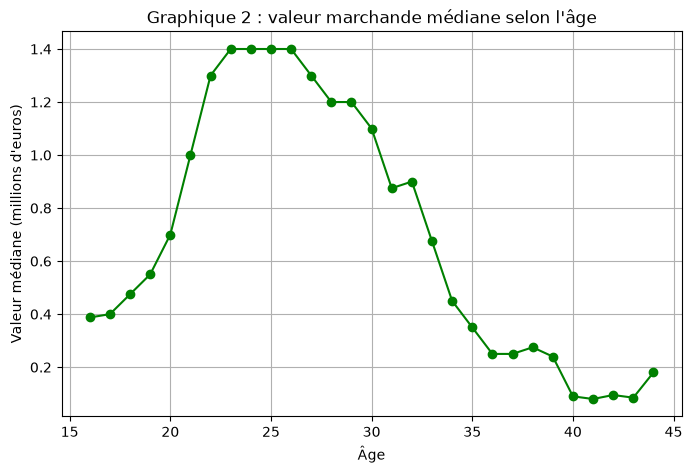

In [39]:
# Graphique 2 : valeur médiane selon l'âge
plt.plot(valeur_par_age.index, valeur_par_age.values, marker="o", color="green")
plt.title("Graphique 2 : valeur marchande médiane selon l'âge")
plt.xlabel("Âge")
plt.ylabel("Valeur médiane (millions d'euros)")
plt.grid(True)
plt.show()

La courbe monte jusqu'à un plateau d'environ **1,4 M€ entre 23 et 26 ans**, puis redescend (0,45 M€ à 34 ans). Mais cette courbe mélange des joueurs de niveaux très différents : les jeunes sont souvent moins bien notés. Pour comparer à niveau égal, on regarde les très bons joueurs (note 80 ou plus).

In [40]:
bons = df[df["overall"] >= 80].copy()
bons["tranche_age"] = pd.cut(bons["age"], [0, 21, 25, 29, 60],
                             labels=["21 ans ou moins", "22-25 ans", "26-29 ans", "30 ans et plus"])

resultat = bons.groupby("tranche_age", observed=True)["valeur_M"].agg(["count", "median"]).round(1)
resultat.columns = ["nb_joueurs", "valeur_mediane_M"]
resultat

,nb_joueurs,valeur_mediane_M
tranche_age,,
21 ans ou moins,16,48.2
22-25 ans,132,41.5
26-29 ans,187,30.5
30 ans et plus,162,18.5


**Réponse :** la valeur augmente fortement jusqu'à environ 25 ans, puis diminue, et la baisse est très marquée après 30 ans. **À niveau égal (note 80 ou plus)**, le marché paie la jeunesse : la valeur médiane passe de **48 M€** (21 ans ou moins) à **18,5 M€** (30 ans et plus). Attention : le groupe des 21 ans ou moins ne compte que 16 joueurs, donc ce chiffre est à prendre avec prudence ; le groupe 22-25 ans (132 joueurs, 41,5 M€) confirme la tendance.

## 6. Question 3 : différences de profil entre les postes

In [41]:
stats_poste = ["attacking_finishing", "attacking_short_passing", "skill_dribbling",
               "mentality_vision", "defending_standing_tackle",
               "mentality_interceptions", "power_strength", "movement_sprint_speed",
               "goalkeeping_diving", "goalkeeping_reflexes"]

profil = df.groupby("poste")[stats_poste].mean().round(0)
profil.T

poste,Attaquant,Défenseur,Gardien,Milieu
attacking_finishing,66.0,37.0,10.0,57.0
attacking_short_passing,60.0,61.0,29.0,67.0
skill_dribbling,65.0,54.0,13.0,66.0
mentality_vision,57.0,48.0,40.0,63.0
defending_standing_tackle,29.0,66.0,13.0,53.0
mentality_interceptions,27.0,63.0,14.0,51.0
power_strength,67.0,70.0,59.0,61.0
movement_sprint_speed,72.0,67.0,35.0,69.0
goalkeeping_diving,10.0,10.0,65.0,10.0
goalkeeping_reflexes,10.0,10.0,65.0,10.0


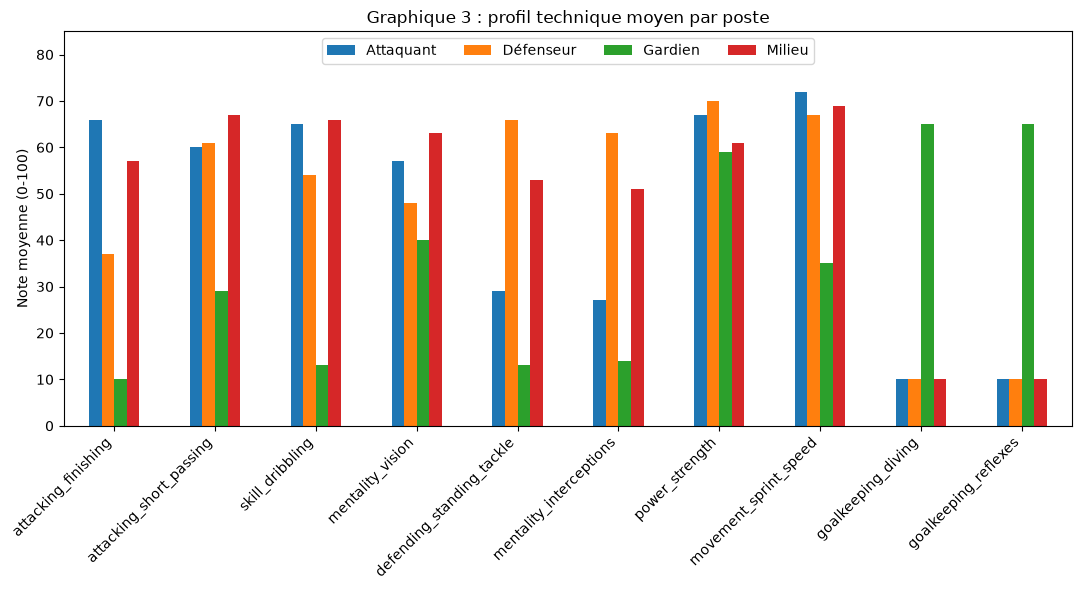

In [42]:
# Graphique 3 : profil moyen par poste
profil.T.plot(kind="bar", figsize=(11, 6))
plt.title("Graphique 3 : profil technique moyen par poste")
plt.ylabel("Note moyenne (0-100)")
plt.ylim(0, 85)
plt.legend(ncol=4, loc="upper center")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Réponse :** les profils sont **très différents** selon le poste :
- **Attaquants :** meilleurs en finition (66) et en vitesse de sprint (72), mais faibles en tacles (29) et interceptions (27).
- **Défenseurs :** meilleurs en tacles (66), interceptions (63) et force (70), mais faibles en finition (37).
- **Milieux :** profil le plus complet, avec les meilleures passes courtes (67), vision (63) et dribbles (66).
- **Gardiens :** profil à part : leurs statistiques de gardien (plongeon, réflexes : 65) sont élevées, alors que tout le reste est faible. Leur note n'est pas comparable à celle des joueurs de champ.



## 7. Question 4 : comment repérer un joueur au bon rapport qualité-prix ?

Nous procédons en quatre temps : (a) le prix suit-il la note ? (b) existe-t-il des joueurs moins chers que leurs pairs ? (c) à note égale, comment le prix varie-t-il avec l'âge ? (d) quels candidats proposer ?

### 7.1 Le prix suit la note

Corrélation note / valeur (Spearman) : 0.87


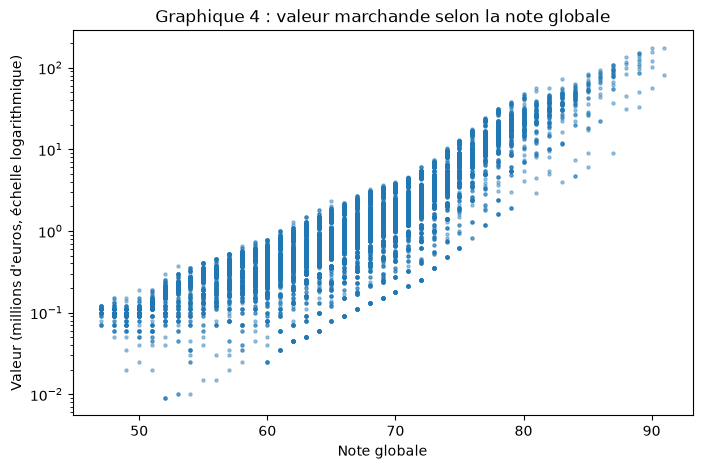

In [43]:
# Lien entre note et valeur (corrélation de rang de Spearman)
print("Corrélation note / valeur (Spearman) :", round(df["valeur_M"].corr(df["overall"], method="spearman"), 2))

# Graphique 4 : valeur selon la note
plt.scatter(df["overall"], df["valeur_M"], s=5, alpha=0.4)
plt.yscale("log")
plt.title("Graphique 4 : valeur marchande selon la note globale")
plt.xlabel("Note globale")
plt.ylabel("Valeur (millions d'euros, échelle logarithmique)")
plt.show()

### 7.2 Y a-t-il des joueurs moins chers que leurs pairs ?

On compare chaque joueur à ses **pairs** : mêmes note, **potentiel**, poste et tranche d'âge. Un écart négatif signifie que le joueur est moins cher que la valeur médiane de ses pairs. (Nous avons d'abord testé sans le potentiel, mais les « bonnes affaires » trouvées avaient simplement un potentiel plus faible : il faut donc le garder dans la comparaison.)

In [44]:
df["tranche_age"] = pd.cut(df["age"], [0, 21, 25, 29, 60],
                           labels=["21 ou moins", "22-25", "26-29", "30 et plus"])

groupe = df.groupby(["overall", "potential", "poste", "tranche_age"], observed=True)["valeur_M"]
df["valeur_mediane_pairs"] = groupe.transform("median")
df["nb_pairs"] = groupe.transform("count")

# Écart en % : négatif = moins cher que les pairs
df["ecart_pct"] = (df["valeur_M"] / df["valeur_mediane_pairs"] - 1) * 100

# Bons joueurs de 27 ans ou moins, avec au moins 5 pairs pour comparer
comparables = df[(df["overall"] >= 75) & (df["age"] <= 27) & (df["nb_pairs"] >= 5)]
print("Joueurs comparables :", len(comparables))
print(comparables["ecart_pct"].describe().round(1))

print()
print("Les 5 joueurs les moins chers par rapport à leurs pairs :")
comparables.sort_values("ecart_pct").head(5)[["short_name", "age", "poste", "overall", "potential",
                                               "valeur_M", "valeur_mediane_pairs", "ecart_pct"]].round(1)

Joueurs comparables : 399
count    399.0
mean       1.1
std        4.6
min      -13.3
25%        0.0
50%        0.0
75%        3.8
max       14.3
Name: ecart_pct, dtype: float64

Les 5 joueurs les moins chers par rapport à leurs pairs :


,short_name,age,poste,overall,potential,valeur_M,valeur_mediane_pairs,ecart_pct
1782,Pol Lozano,25,Milieu,75,78,6.5,7.5,-13.3
392,Z. Youssouf,25,Milieu,77,82,14.0,16.0,-12.5
1865,I. Sissoko,27,Milieu,76,77,7.5,8.5,-11.8
2502,Ander Guevara,27,Milieu,76,77,7.5,8.5,-11.8
629,H. Nicolussi Caviglia,25,Milieu,75,80,7.5,8.5,-11.8


**Résultat :** pour des joueurs de même note, même potentiel, même poste et même âge, les prix sont presque identiques : l'écart médian est de **0 %** et les écarts extrêmes vont de **-13 % à +14 %**. La valeur du jeu suit donc une formule (note, potentiel, âge, poste) et **il n'existe pas de joueur « caché » très sous-évalué**. Le vrai levier de rapport qualité-prix est ailleurs : l'âge.

### 7.3 À note égale, le prix baisse fortement avec l'âge

             nb_joueurs  valeur_mediane_M
tranche_age                              
21 ou moins          93              16.5
22-25               384              14.0
26-29               478               8.5
30 et plus          387               5.0


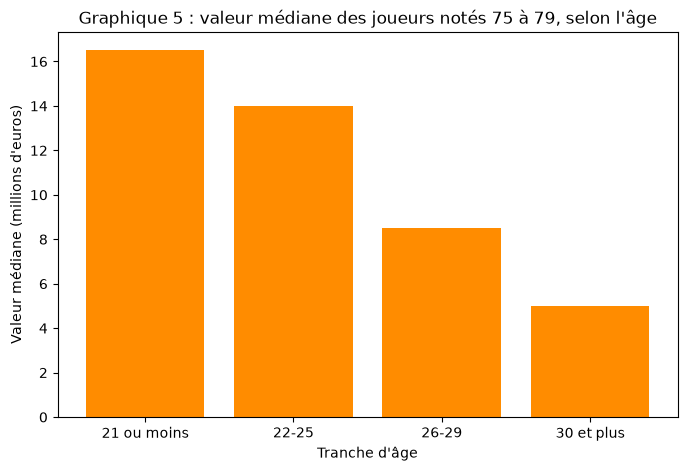

In [45]:
# Joueurs de note 75 à 79 : valeur médiane selon la tranche d'age
niveau = df[(df["overall"] >= 75) & (df["overall"] <= 79)]
prix_age = niveau.groupby("tranche_age", observed=True)["valeur_M"].agg(["count", "median"]).round(1)
prix_age.columns = ["nb_joueurs", "valeur_mediane_M"]
print(prix_age)

# Graphique 5 : même niveau, prix selon l'âge
plt.bar(prix_age.index.astype(str), prix_age["valeur_mediane_M"], color="darkorange")
plt.title("Graphique 5 : valeur médiane des joueurs notés 75 à 79, selon l'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Valeur médiane (millions d'euros)")
plt.show()

Pour un même niveau (note de 75 à 79), un joueur de 30 ans ou plus coûte en médiane **5 M€**, contre **14 M€** pour un joueur de 22 à 25 ans, soit près de trois fois moins.

### 7.4 Candidats à étudier

In [46]:
# Court terme : bons joueurs (note >= 76) à 10 M€ maximum, les 3 meilleurs par poste
budget = df[(df["overall"] >= 76) & (df["valeur_M"] <= 10)]
print("Joueurs notés 76 ou plus et valant 10 M€ ou moins :", len(budget))
print("Âge médian de ces joueurs :", budget["age"].median(), "ans")

meilleurs = budget.sort_values(["overall", "valeur_M"], ascending=[False, True]).groupby("poste").head(3)
meilleurs.sort_values(["poste", "overall"], ascending=[True, False])[["short_name", "age", "poste", "overall", "valeur_M"]]

Joueurs notés 76 ou plus et valant 10 M€ ou moins : 421
Âge médian de ces joueurs : 31.0 ans


,short_name,age,poste,overall,valeur_M
374,Á. Di María,37,Attaquant,82,10.000000
72,I. Perišić,36,Attaquant,81,8.500000
1005,P. Aubameyang,36,Attaquant,81,9.000000
2417,F. Acerbi,37,Défenseur,84,7.500000
1665,N. Otamendi,37,Défenseur,82,5.500000
2403,Nacho Fernández,35,Défenseur,82,8.000000
15002,Y. Sommer,36,Gardien,87,9.000000
15924,P. Gulácsi,35,Gardien,85,6.000000
16154,De Gea,34,Gardien,85,9.000000
180,Parejo,36,Milieu,82,9.500000


In [47]:
# Long terme : jeunes à fort potentiel et peu chers
jeunes = df[(df["age"] <= 21) & (df["potential"] >= 80) & (df["valeur_M"] <= 15)]
jeunes = jeunes.sort_values("potential", ascending=False).head(10)

jeunes[["short_name", "age", "poste", "overall", "potential", "valeur_M"]]

,short_name,age,poste,overall,potential,valeur_M
6790,J. Mokio,17,Milieu,70,89,3.8
6665,R. Ngumoha,16,Milieu,68,88,3.3
1780,G. Read,19,Défenseur,75,88,13.0
8106,E. Bitshiabu,20,Défenseur,75,87,12.5
4544,Pablo García,18,Milieu,68,87,3.1
7692,F. Jeltsch,18,Défenseur,72,87,5.0
6206,L. Vušković,18,Défenseur,72,87,5.0
2332,K. Smit,19,Milieu,72,87,5.5
11283,F. Camarda,17,Attaquant,65,87,2.3
7516,J. Duranville,19,Milieu,72,87,5.5


**Réponse :** pour repérer un bon rapport qualité-prix, il faut d'abord choisir l'horizon du club. **À court terme**, les joueurs de 30 ans ou plus offrent le meilleur niveau pour le prix (par exemple 421 joueurs notés 76 ou plus valent 10 M€ ou moins, avec un âge médian de 31 ans). **À long terme**, les jeunes de 21 ans ou moins avec un potentiel élevé coûtent encore peu, mais leur prix montera s'ils progressent.